<a href="https://colab.research.google.com/github/FDB1228/RecSys_MovieLens/blob/main/RecSys_MovieLens.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Рекомендательные системы на MovieLens-1M

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/<ваш-логин>/<репозиторий>/blob/main/RecSys_MovieLens.ipynb)


---

Учебный проект по основам рекомендательных систем. Мы строим «лесенку» моделей, от тривиального бейзлайна до нейросети, и сравниваем их по одному и тому же честному протоколу: разбиение по времени, полное ранжирование каталога, отдельные срезы для знакомых и новых пользователей, доверительные интервалы вместо единичных чисел.

Цель проекта не в том, чтобы выжать максимум метрики, а в том, чтобы разобраться, **как устроены основные семейства алгоритмов, почему они ведут себя по-разному и как корректно сравнивать их между собой**. Поэтому в блокноте оставлены и неудачные эксперименты: именно они показывают, как проявляется popularity bias.

**Содержание**

0. Введение и постановка задачи
1. Данные и разбиение по времени
2. Метрики
3. Бейзлайн: популярное
4. $Item-kNN$ и $popularity bias$
5. ALS: матричная факторизация
6. Двухбашенная модель: $logQ$-коррекция и холодный старт
7. Итоговая оценка: $bootstrap$ и парные сравнения
8. Выводы, ограничения, дальнейшие шаги, литература

## Главные выводы

Числа ниже взяты из итоговой оценки на тестовой части (раздел 7). Все модели настроены только на validation выборке, test выборка использовалась один раз.

* **«Популярное» – сильный бейзлайн.** Для знакомых пользователей (n = 1159) $Recall@10 = 0.0567$, $NDCG@10 = 0.2120$. Для новых пользователей ни одна из наших моделей не оказалась значимо лучше него.
* **Персонализация на знакомых пользователях работает, но разные метрики дают разный порядок моделей.** По $Recall@10$ наибольшее значение у $ALS$ (0.0717; выигрыш у популярного: +0.0151 (95% ДИ [0.0081; 0.0226])), по $NDCG@10$ – у $item-kNN$ (0.2411 против 0.2247 у $ALS$; $ALS − kNN$: −0.0164 (95% ДИ [−0.0272; −0.0057])).
* **Двухбашенная модель (ID-эмбеддинги плюс пол, возраст, профессия и жанры) статистически не отличима от $ALS$:** разность $Recall@10$ равна −0.0044 (95% ДИ [−0.0105; 0.0015]).
* **logQ-коррекция критична.** На validation $Recall@10$ двухбашенной модели без неё 0.0093, с ней 0.0684. Без поправки модель сама «штрафует» популярные фильмы и рекомендует преимущественно редкие.
* **ID dropout помогает на новых пользователях.** На validation прирост $Recall@10$ +0.0099 (95% ДИ [0.0051; 0.0153]) (n = 611); на test (всего 29 новых пользователей) направление то же: +0.0258 (95% ДИ [0.0087; 0.0456]).
* **Точность и разнообразие тянут в разные стороны.** $Coverage@10$: у популярного 0.038, у $ALS 0.197$. Одна метрика не говорит, какая модель «лучше».

---
## 0. Введение и постановка задачи

### Что такое рекомендательная задача

Пусть $U$ – множество пользователей, $I$ – множество объектов (у нас это фильмы), а $R \in \mathbb{R}^{|U| \times |I|}$ – матрица взаимодействий: элемент $r_{ui}$ описывает, как пользователь $u$ отреагировал на объект $i$. Эта матрица **сильно разрежена**: подавляющее большинство пар $(u, i)$ нам неизвестно, причём чаще всего потому, что пользователь не видел фильм, а не потому, что фильм ему не понравился.

Мы решаем задачу **top-$K$ рекомендаций**: для пользователя $u$ нужно выдать упорядоченный список из $K$ объектов, которые он ещё не видел и которые, скорее всего, ему понравятся. Это отличается от предсказания оценки (rating prediction): нас интересует не точное значение $r_{ui}$, а правильный **порядок** объектов в начале списка.

### Явная и неявная обратная связь

* **Explicit feedback** – пользователь прямо говорит, насколько ему понравилось (оценка от 1 до 5). Сигнал информативный, но его мало.
* **Implicit feedback** – факт взаимодействия (просмотр, клик, покупка). Сигнала много, но явных негативов нет: отсутствие взаимодействия не означает «не нравится».

В MovieLens оценки явные, но мы переводим задачу в «неявную» постановку, как в реальных системах:

$$
p_{ui} = \begin{cases} 1, & r_{ui} \ge 4, \\ 0, & \text{иначе.} \end{cases}
$$

Значение $p_{ui} = 1$ называем **положительным взаимодействием**. Фильмы, которые пользователь уже оценил (с любой оценкой), мы исключаем из его выдачи: рекомендовать их заново бессмысленно.

### Данные

[MovieLens-1M](https://grouplens.org/datasets/movielens/1m/) – около миллиона оценок фильмов по шкале 1–5 (Harper & Konstan, 2015). Три файла: `ratings.dat` (пользователь, фильм, оценка, время), `users.dat` (пол, возрастная группа, профессия, почтовый индекс) и `movies.dat` (название, жанры). Лицензия допускает только исследовательское использование, поэтому сами данные в репозиторий не включены: блокнот скачивает их с сайта GroupLens.

### Принципы честной оценки

1. **Разбиение по времени.** Модель обучается на прошлом, проверяется на будущем (раздел 1).
2. **Полное ранжирование каталога.** Оцениваем список по всем фильмам, а не по небольшой выборке негативов, исключая только уже виденные.
3. **Срезы по пользователям.** Отдельно считаем метрики для *знакомых* (warm) пользователей, у которых есть история в обучающей выборке, и для *новых* (cold), у которых её нет.
4. **Доверительные интервалы.** Сравниваем модели не по одному числу, а по bootstrap-интервалам и парным разностям (раздел 7).

### План: «лесенка» моделей

| Шаг | Модель | Чему учит |
|---|---|---|
| 1 | Популярное | задаёт планку; показывает, что такое popularity bias |
| 2 | Item-kNN | коллаборативная фильтрация «по соседям»; почему косинусная близость любит популярное |
| 3 | ALS | латентные факторы, неявная обратная связь, переобучение и выбор гиперпараметров |
| 4 | Two-tower | нейросетевой retrieval, признаки пользователей и фильмов, logQ-коррекция, холодный старт |


In [1]:
!pip install implicit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 66.1 MB/s eta 0:00:00


In [2]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import itertools
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from implicit.als import AlternatingLeastSquares


---
## 1. Данные и разбиение по времени

### Загрузка

Скачиваем архив MovieLens-1M с сайта GroupLens и читаем таблицу оценок. Датафрейм оценок назовём `ratings`.

In [3]:
import urllib.request, zipfile

url = "https://files.grouplens.org/datasets/movielens/ml-1m.zip"
urllib.request.urlretrieve(url, "ml-1m.zip")
zipfile.ZipFile("ml-1m.zip").extractall("data")


In [4]:
import pandas as pd
ratings = pd.read_csv("data/ml-1m/ratings.dat", sep="::", engine="python",
                names=["user_id", "movie_id", "rating", "ts"])
ratings["dt"] = pd.to_datetime(ratings["ts"], unit="s")
print(ratings.shape, ratings["dt"].min(), ratings["dt"].max())
print(ratings["rating"].value_counts().sort_index())

(1000209, 5) 2000-04-25 23:05:32 2003-02-28 17:49:50
rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64


В таблице 1 000 209 оценок, поставленных в период с 2000-04-25 по 2003-02-28. Распределение оценок смещено вверх: оценки 4 и 5 составляют 57.5% всех оценок (4 — 34.9%, 5 — 22.6%), а 3 — 26.1%. Это типичная особенность явных оценок: люди охотнее оценивают то, что им понравилось.

Посмотрим на первые строки.

In [5]:
ratings.head()

,user_id,movie_id,rating,ts,dt
0,1,1193,5,978300760,2000-12-31 22:12:40
1,1,661,3,978302109,2000-12-31 22:35:09
2,1,914,3,978301968,2000-12-31 22:32:48
3,1,3408,4,978300275,2000-12-31 22:04:35
4,1,2355,5,978824291,2001-01-06 23:38:11


Столбец `ts` — это **Unix-время**: число секунд, прошедших с 1 января 1970 года (UTC) до момента, когда пользователь поставил оценку. Например, `978300760` соответствует 31 декабря 2000 года. Для людей оно неудобно, поэтому мы дополнительно создали столбец `dt` через `pd.to_datetime(..., unit="s")`, а для сортировки и разбиения достаточно самого `ts`: большее число означает более позднюю оценку. Важная деталь: это время **оценки**, а не просмотра. Пользователи часто ставят оценки пачкой за одну сессию, поэтому вся «история» человека может быть сжата в короткий промежуток.

### Почему разбиение должно быть по времени

Самое простое, что приходит в голову, — случайно отложить 20% оценок на тест. Но в реальной системе в момент рекомендации известно **только прошлое**. При случайном разбиении модель видит в обучении оценки, поставленные *после* тех, что лежат в тесте: поведение того же пользователя «в будущем», сдвиги вкусов, всплески популярности фильмов. Это **утечка данных из будущего** (data leakage): метрики завышены, а в проде такой точности не будет. Наше правило: **время в обучении всегда раньше, чем время в проверке**.

Есть два распространённых способа:

* **Глобальный сдвиг по времени.** Выбираем моменты $t_{val}$ и $t_{test}$: всё, что раньше $t_{val}$, — обучение, между ними — валидация, после $t_{test}$ — тест. Ближе всего к реальности; побочный эффект — в проверке появляются новые пользователи и фильмы (**холодный старт**).
* **Leave-last-out.** У каждого пользователя последнее взаимодействие уходит в тест. Удобно, но возникает тонкая утечка: «последнее» событие одного пользователя может быть раньше, чем «прошлое» другого, и модель косвенно использует будущее через других пользователей.

Мы используем первый способ: границы задаём квантилями времени (0.8 и 0.9), поэтому выборки получаются примерно в пропорции 80 / 10 / 10. Валидацию (val) используем для подбора гиперпараметров, тест (test) трогаем **один раз в самом конце**, иначе итоговое число окажется подогнанным под него.

In [6]:
ratings = ratings.sort_values("ts")
t_val  = ratings["ts"].quantile(0.8)
t_test = ratings["ts"].quantile(0.9)

train = ratings[ratings["ts"] <  t_val]
val   = ratings[(ratings["ts"] >= t_val) & (ratings["ts"] < t_test)]
test  = ratings[ratings["ts"] >= t_test]

print(len(train), len(val), len(test))

new_users = set(test["user_id"])  - set(train["user_id"])
new_items = set(test["movie_id"]) - set(train["movie_id"])
print("новые пользователи в test:", len(new_users) / test["user_id"].nunique())
print("новые фильмы в test:", len(new_items) / test["movie_id"].nunique())

800164 100024 100021
новые пользователи в test: 0.1654259718775848
новые фильмы в test: 0.00968594071030232


Получилось 800 164 / 100 024 / 100 021 оценок. Важнее другое: в тесте **16.5% пользователей новые** (их нет в обучающей части), тогда как новых фильмов всего **1.0%**. Каталог почти не меняется, зато поток пользователей продолжается. Поэтому *холодный старт по пользователям* — реальная проблема этого датасета, а по фильмам — почти нет.

Заведём два среза теста: знакомые и новые пользователи. Дальше мы везде будем считать метрики отдельно для этих групп.

In [7]:
warm_users = set(train["user_id"])
test_warm = test[test["user_id"].isin(warm_users)]    # знакомые пользователи
test_cold = test[~test["user_id"].isin(warm_users)]   # новые пользователи

---
## 2. Метрики

Для каждого пользователя $u$ у нас есть:

* $\mathrm{Rel}_u$ — множество его **релевантных** объектов в проверочной выборке (фильмы с оценкой $\ge 4$, поставленной в проверяемый период);
* $L_u = (i_1, \dots, i_K)$ — наш список рекомендаций, упорядоченный по убыванию оценки модели, без уже виденных фильмов.

### $Recall@K$

Доля релевантных объектов, которые попали в топ-$K$:

$$
\mathrm{Recall@}K(u) = \frac{|\mathrm{Rel}_u \cap L_u|}{|\mathrm{Rel}_u|}.
$$

Метрика не учитывает порядок внутри списка: попадание на первом и на десятом месте даёт одно и то же.

### $NDCG@K$

Учитывает позицию попадания. Вклад найденного объекта на позиции $p$ уменьшается как $1 / \log_2(p + 1)$:

$$
\mathrm{DCG@}K(u) = \sum_{p=1}^{K} \frac{\mathbb{1}[i_p \in \mathrm{Rel}_u]}{\log_2(p + 1)}, \qquad
\mathrm{IDCG@}K(u) = \sum_{p=1}^{\min(|\mathrm{Rel}_u|,\, K)} \frac{1}{\log_2(p + 1)}, \qquad
\mathrm{NDCG@}K(u) = \frac{\mathrm{DCG@}K(u)}{\mathrm{IDCG@}K(u)}.
$$

$\mathrm{IDCG}$ — значение DCG для идеального списка, в котором все релевантные объекты стоят в начале. Поэтому NDCG лежит в диапазоне от 0 до 1.

**Пример.** Допустим, у пользователя один релевантный фильм, а мы показываем топ-3. Если он на первом месте, то $\mathrm{Recall@3} = 1$ и $\mathrm{NDCG@3} = 1 / \log_2 2 = 1$. Если он на третьем месте, то $\mathrm{Recall@3} = 1$ по-прежнему, а $\mathrm{NDCG@3} = (1 / \log_2 4) / 1 = 0.5$. Recall не видит разницы, NDCG видит.

Обе метрики усредняются по пользователям. Мы везде берём $K = 10$.

### $Coverage@K$ (охват каталога)

Доля всех объектов каталога, которые хотя бы одному пользователю попали в топ-$K$:

$$
\mathrm{Coverage@}K = \frac{\left|\bigcup_{u} L_u\right|}{|I|}.
$$

Низкий охват означает, что система рекомендует всем почти одно и то же. Но сам по себе высокий охват не признак качества: случайные рекомендации дают максимальный охват. Читаем его **только вместе с точностью**.

### Оговорка про абсолютные значения

Объекты, которые пользователь не оценил, мы считаем нерелевантными, хотя он мог бы их оценить высоко. Поэтому абсолютные значения метрик занижены и малы. Сравнивать имеет смысл модели между собой, а не с «идеалом».

---
## 3. Бейзлайн: популярное

Самая простая рекомендация не зависит от пользователя: показать всем одни и те же «лучшие» фильмы. Такой бейзлайн важен: он задаёт планку, ниже которой персонализация бессмысленна. Есть два естественных варианта.

1. **По числу положительных оценок.** Фильм тем выше, чем больше людей оценили его на 4 или 5.
2. **По средней оценке с поправкой на число голосов.** Сырая средняя плоха: фильм с единственной оценкой 5 окажется «лучше» фильма с тысячью оценок и средним 4.6. Поэтому используют **демпфированное (байесовское) среднее**:

$$
\mathrm{score}_i = \frac{v_i R_i + m\, C}{v_i + m},
$$

где $R_i$ — средняя оценка фильма, $v_i$ — число его оценок, $C$ — средняя оценка по всему датасету, $m$ — сила «априорного убеждения» (гиперпараметр). При малом $v_i$ оценка подтягивается к общей средней $C$, при большом остаётся близкой к $R_i$.

Из выдачи убираем фильмы, которые пользователь уже оценил в обучающей выборке.

In [8]:
K = 10
train_pos = train[train["rating"] >= 4]
val_pos   = val[val["rating"] >= 4]

# 1) популярность по числу положительных оценок
pop_count = train_pos["movie_id"].value_counts()

# 2) демпфированное среднее
C = train["rating"].mean()
m = 20
g = train.groupby("movie_id")["rating"].agg(["mean", "count"])
g["score"] = (g["count"] * g["mean"] + m * C) / (g["count"] + m)
pop_damped = g["score"].sort_values(ascending=False)

def recall_at_k(rank, train_df, target_pos, k=10):
    seen  = train_df.groupby("user_id")["movie_id"].apply(set)
    truth = target_pos.groupby("user_id")["movie_id"].apply(set)
    scores = []
    for u, rel in truth.items():
        s = seen.get(u, set())
        rec = [i for i in rank.index if i not in s][:k]
        scores.append(len(set(rec) & rel) / len(rel))
    return sum(scores) / len(scores)

print("count :", recall_at_k(pop_count,  train, val_pos, K))
print("damped:", recall_at_k(pop_damped, train, val_pos, K))

count : 0.06073490725413098
damped: 0.028389091476531052


Счётчик положительных оценок даёт $Recall@10 = 0.0607$, а демпфированное среднее при $m = 20$ — только $0.0284$. Выигрывает популярность, и здесь нет ничего парадоксального. Recall отвечает на вопрос «угадали ли мы то, что пользователь реально оценил высоко», а чтобы оценить фильм, его надо сначала увидеть. Популярные фильмы видят и оценивают гораздо больше людей, поэтому они чаще попадают в проверочные положительные оценки, независимо от того, «лучше» ли они. Демпфированное среднее ищет *качество*, а метрика поощряет *охват аудитории*. Это и есть **popularity bias**: и данные, и метрика смещены в сторону популярного.

Проверим это, подбирая $m$. При очень большом $m$ формула вырождается:

$$
\mathrm{score}_i = C + \frac{v_i\,(R_i - C)}{v_i + m} \;\xrightarrow{\,m \to \infty\,}\; C,
$$

то есть все оценки сжимаются к $C$, а порядок определяется произведением $v_i (R_i - C)$: числом голосов, умноженным на превышение над средним. Рейтинг плавно превращается в ранжирование по популярности.

In [9]:
for m in [0, 20, 100, 500, 2000, 10000]:
    g["score"] = (g["count"] * g["mean"] + m * C) / (g["count"] + m)
    pop = g["score"].sort_values(ascending=False)
    print(m, round(recall_at_k(pop, train, val_pos, K), 4))

0 0.0
20 0.0284
100 0.035
500 0.051
2000 0.0585
10000 0.0605



| m | Recall@10 |
|---|---:|
| 0 | 0.0000 |
| 20 | 0.0284 |
| 100 | 0.0350 |
| 500 | 0.0510 |
| 2000 | 0.0585 |
| 10000 | 0.0605 |

$Recall@10$ монотонно растёт вместе с $m$ и упирается в значение чистого счётчика. Это не значит, что «чем больше $m$, тем лучше модель»: мы просто движемся от ранжирования по качеству к ранжированию по популярности. Подбирать $m$ по одному $Recall$ бессмысленно, оптимум лежит на границе. Дальше за планку берём **счётчик положительных оценок**.

---
## 4. Item-kNN и popularity bias

### Идея

Популярное одинаково для всех. Чтобы персонализировать, используем историю пользователя: рекомендуем фильмы, **похожие на те, что он уже оценил высоко**. Для этого нужно представить фильм вектором.

Пусть $X \in \{0, 1\}^{|U| \times |I|}$ — матрица положительных взаимодействий: $X_{ui} = p_{ui}$. Столбец $x_i$ — это фильм $i$, описанный множеством пользователей, которые его высоко оценили. Похожесть двух фильмов измеряем **косинусной близостью**:

$$
\cos(i, j) = \frac{x_i^{\top} x_j}{\lVert x_i \rVert\, \lVert x_j \rVert} = \frac{|U_i \cap U_j|}{\sqrt{|U_i|\,|U_j|}},
$$

где $U_i$ — множество пользователей, высоко оценивших фильм $i$. Скалярное произведение векторов из нулей и единиц — это число общих «лайкеров», а деление на нормы убирает перекос из-за разной популярности (но не полностью, об этом ниже).

Пусть $S$ — матрица близостей между фильмами с нулевой диагональю (фильм не рекомендует сам себя). Оценка релевантности фильма $i$ для пользователя $u$ — сумма близостей $i$ ко всем фильмам, которые $u$ высоко оценил:

$$
\hat{s}_{ui} = \sum_{j} X_{uj}\, S_{ji}, \qquad \hat{S} = X S.
$$

Это не предсказанная оценка по шкале 1–5, а безразмерный балл; для ранжирования важен только порядок внутри строки.

In [10]:
import numpy as np, scipy.sparse as sp
from sklearn.preprocessing import normalize

# индексы: строим по всему train, чтобы совпадали для всех матриц
u_cat = train["user_id"].astype("category")
i_cat = train["movie_id"].astype("category")
u_map = {u: k for k, u in enumerate(u_cat.cat.categories)}
i_map = {i: k for k, i in enumerate(i_cat.cat.categories)}
n_u, n_i = len(u_map), len(i_map)

def to_matrix(df):
    rows = df["user_id"].map(u_map).values
    cols = df["movie_id"].map(i_map).values
    return sp.csr_matrix((np.ones(len(df)), (rows, cols)), shape=(n_u, n_i))

X_pos  = to_matrix(train_pos)   # 1, если пользователь высоко оценил фильм
X_seen = to_matrix(train)       # 1, если пользователь вообще оценил фильм

Xn = normalize(X_pos, axis=0)   # каждый фильм-столбец приводим к длине 1
S = (Xn.T @ Xn).tocsr()         # косинусная близость фильмов
S.setdiag(0)                    # фильм не рекомендует сам себя

scores = (X_pos @ S).toarray()
scores[X_seen.nonzero()] = -np.inf   # уже виденные не рекомендуем

def recall_from_scores(scores, truth_df, k=10):
    inv_i = np.array(i_cat.cat.categories)
    truth = truth_df.groupby("user_id")["movie_id"].apply(set)
    res = []
    for u, rel in truth.items():
        if u not in u_map:       # холодные пользователи пропускаем
            continue
        top = np.argpartition(-scores[u_map[u]], k)[:k]
        res.append(len(set(inv_i[top]) & rel) / len(rel))
    return np.mean(res)

print("item-kNN:", recall_from_scores(scores, val_pos))

# популярное на тех же пользователях, для честного сравнения
pop_vec = np.asarray(X_pos.sum(axis=0)).ravel()
scores_pop = np.tile(pop_vec, (n_u, 1)).astype(float)
scores_pop[X_seen.nonzero()] = -np.inf
print("popular :", recall_from_scores(scores_pop, val_pos))

item-kNN: 0.05628345848349352
popular : 0.047742834424603295


$Item-kNN$ даёт $Recall@10 = 0.0563$ против $0.0477$ у популярного. Обратите внимание, что значение «популярного» здесь другое (было 0.0607): теперь мы усредняем только по **знакомым** пользователям, потому что у новых в kNN нет истории и считать нечего.

Проверим гипотезу, откуда разница: возможно, новые пользователи в основном оценивают самые популярные фильмы, и для них «популярное» работает особенно хорошо.

In [11]:
warm = set(train["user_id"])
v_warm = val_pos[val_pos["user_id"].isin(warm)]
v_cold = val_pos[~val_pos["user_id"].isin(warm)]
print("warm:", recall_at_k(pop_count, train, v_warm, K))
print("cold:", recall_at_k(pop_count, train, v_cold, K))
print("холодных пользователей:", v_cold["user_id"].nunique(), "из", val_pos["user_id"].nunique())

warm: 0.047742834424603295
cold: 0.07119660910704036
холодных пользователей: 611 из 1103


Для новых пользователей «популярное» даёт $Recall@10 = 0.0712$, для знакомых – $0.0477$. Новые пользователи составляют 55% проверяемой выборки (611 из 1103), поэтому они сильно влияют на общую цифру. Гипотеза согласуется с данными (возможное объяснение: на старте люди оценивают самые известные фильмы), но напрямую мы её не проверяли. Практический вывод: **метрики нужно всегда считать раздельно по знакомым и новым пользователям**, что мы и будем делать в разделе 7.

### Почему косинус всё равно любит популярное

Допустим, два фильма абсолютно независимы: тот, кто любит один, не любит и не нелюбит другой. Если $N$ – число пользователей, то ожидаемое число общих «лайкеров» равно $n_i n_j / N$, и косинус получается

$$
\cos(i, j) \approx \frac{n_i n_j / N}{\sqrt{n_i n_j}} = \frac{\sqrt{n_i n_j}}{N}.
$$

То есть даже у **несвязанных** фильмов он не нулевой, а растёт вместе с популярностью обоих. Хит «похож» на всё подряд, и его суммарный балл высок почти у всех пользователей. Деления на нормы недостаточно.

### Эксперимент 1: штраф за популярность

Самое простое лекарство — дополнительно делить балл на популярность кандидата:

$$
\hat{s}^{(\beta)}_{ui} = \frac{\hat{s}_{ui}}{n_i^{\beta}},
$$

где $n_i$ — число положительных оценок фильма, $\beta \ge 0$ — сила штрафа. При $\beta = 0$ получаем исходный kNN. Параллельно считаем охват каталога.

In [12]:
n_pos = np.maximum(np.asarray(X_pos.sum(axis=0)).ravel(), 1)

def coverage(sc, k=10):
    top = np.argpartition(-sc, k, axis=1)[:, :k]
    return len(np.unique(top)) / sc.shape[1]

for beta in [0, 0.25, 0.5, 0.75, 1.0]:
    adj = scores / np.power(n_pos, beta)
    print(beta,
          "recall:", round(recall_from_scores(adj, val_pos), 4),
          "coverage:", round(coverage(adj), 3))

0 recall: 0.0563 coverage: 0.12
0.25 recall: 0.0329 coverage: 0.407
0.5 recall: 0.0 coverage: 0.107
0.75 recall: 0.0 coverage: 0.067
1.0 recall: 0.0 coverage: 0.062



| β | Recall@10 | Coverage@10 |
|---|---:|---:|
| 0 | 0.0563 | 0.12 |
| 0.25 | 0.0329 | 0.407 |
| 0.5 | 0.0000 | 0.107 |
| 0.75 | 0.0000 | 0.067 |
| 1.0 | 0.0000 | 0.062 |

При $\beta = 0.25$ получается понятный компромисс: охват вырос с 0.12 до 0.407, Recall упал с 0.0563 до 0.0329. А вот при $\beta \ge 0.5$ система ломается: Recall равен нулю, а охват *падает*. Привычная логика «больше штраф — больше разнообразия» не работает. Посмотрим, что происходит, — какие фильмы чаще всего попадают в топ-10 при $\beta = 1$:

In [13]:
beta = 1.0
adj = scores / np.power(n_pos, beta)
top = np.argpartition(-adj, 10, axis=1)[:, :10]

vals, counts = np.unique(top, return_counts=True)
order = np.argsort(-counts)[:10]
print("самые частые фильмы в топ-10 (индекс, у скольких пользователей, n_pos):")
for idx in order:
    print(vals[idx], counts[idx], int(n_pos[vals[idx]]))

самые частые фильмы в топ-10 (индекс, у скольких пользователей, n_pos):
915 4503 1
2617 3192 1
3052 3182 1
2312 3157 1
3298 3153 1
1221 3147 1
689 2574 1
2587 2567 1
1414 2551 1
2812 1926 1


У всех десяти самых частых фильмов `n_pos = 1` (в коде нижняя граница равна 1; фильм без положительных оценок имел бы нулевой балл, поэтому, скорее всего, это фильмы ровно с одним «лайкером»). И при этом они попадают в топ-10 у тысяч пользователей: первый — у 4503. Вероятное объяснение: если единственный «лайкер» редкого фильма высоко оценил сотни других, то у этого фильма появляются связи с большой частью каталога, и его балл заметен у многих пользователей. При $\beta = 1$ мы делим на $n_i = 1$ (то есть такие фильмы вообще не штрафуем), а у настоящих хитов делим на тысячи. Хиты обнуляются, шум побеждает. Получается небольшая группа «хаб-фильмов», которые рекомендуются очень многим и почти никогда не угадываются.

Вывод: грубый штраф $1/n^{\beta}$ не отличает «редкий, но надёжный сигнал» от «редкий и шумный».

### Эксперимент 2: shrinkage (сжатие близости)

Стандартная правка: уменьшить близость там, где она оценена по малому числу общих пользователей. Пусть $c_{ij} = |U_i \cap U_j|$ — число общих «лайкеров». Тогда

$$
\tilde{S}_{ij} = \cos(i, j) \cdot \frac{c_{ij}}{c_{ij} + \lambda}.
$$

Если общих пользователей мало, близость сильно урезается, если много — почти не меняется. Гиперпараметр $\lambda$ задаёт, что считать «малым».

In [14]:
C = (X_pos.T @ X_pos).tocoo()
mask = C.row != C.col
r, c, d = C.row[mask], C.col[mask], C.data[mask]
n = np.asarray(X_pos.sum(axis=0)).ravel()

def build_S(lam):
    w = d / np.sqrt(n[r] * n[c]) * d / (d + lam)
    return sp.csr_matrix((w, (r, c)), shape=C.shape)

for lam in [0, 10, 30, 100]:
    sc = (X_pos @ build_S(lam)).toarray()
    sc[X_seen.nonzero()] = -np.inf
    print(lam, "recall:", round(recall_from_scores(sc, val_pos), 4),
          "coverage:", round(coverage(sc), 3))

0 recall: 0.0563 coverage: 0.12
10 recall: 0.0582 coverage: 0.09
30 recall: 0.0576 coverage: 0.077
100 recall: 0.0582 coverage: 0.066



| λ | Recall@10 | Coverage@10 |
|---|---:|---:|
| 0 | 0.0563 | 0.12 |
| 10 | 0.0582 | 0.09 |
| 30 | 0.0576 | 0.077 |
| 100 | 0.0582 | 0.066 |

Shrinkage безопаснее штрафа: Recall не падает, а на фоне шума даже немного растёт. Охват при этом уменьшается: часть «разнообразия» при $\lambda = 0$ была просто шумом от единичных совпадений. Значения не монотонны по $\lambda$, а разница в тысячные доли при таком числе пользователей лежит в пределах случайного шума (строгая проверка — в разделе 7). Для итогового сравнения берём **обычный косинус без поправок**: он проще, а выигрыша от поправок мы не увидели.

### Итоги раздела

* Item-kNN обходит популярное, но скромно.
* Косинусная близость не избавляет от смещения в сторону популярного.
* Грубый штраф за популярность ломает систему, shrinkage безопаснее, но существенного выигрыша не дал.
* Точность и охват тянут в разные стороны, и одной метрикой оптимизировать нельзя.

---
## 5. ALS: матричная факторизация

### Идея

kNN хранит матрицу близостей между фильмами $|I| \times |I|$ и опирается на буквальные совпадения: два фильма похожи, только если у них есть общие пользователи. Матричная факторизация сжимает всех до коротких векторов. Каждому пользователю $u$ ставим в соответствие вектор $x_u \in \mathbb{R}^f$, каждому фильму $i$ — вектор $y_i \in \mathbb{R}^f$ (в нашем случае $f = 32$) так, чтобы скалярное произведение предсказывало интерес:

$$
\hat{p}_{ui} = x_u^{\top} y_i = \sum_{k=1}^{f} x_{uk}\, y_{ik}.
$$

Координаты называются **латентными факторами**: мы не задаём, что они означают, модель сама ищет такие $f$ направлений, которые лучше всего объясняют, кто что лайкает. Иногда фактор неплохо совпадает с жанром или эпохой, но это интерпретация задним числом, а не гарантия; сами числа могут быть отрицательными. Большое скалярное произведение — «вкусы совпали».

### Неявная обратная связь: Hu, Koren, Volinsky (2008)

Для неявных данных стандартный метод минимизирует

$$
\min_{X,\,Y} \sum_{u,i} c_{ui}\,\bigl(p_{ui} - x_u^{\top} y_i\bigr)^2 + \lambda\Bigl(\sum_u \lVert x_u \rVert^2 + \sum_i \lVert y_i \rVert^2\Bigr), \qquad c_{ui} = 1 + \alpha\, p_{ui}.
$$

Ключевые идеи:

1. **Все ячейки матрицы входят в функцию потерь**, и неизвестные считаются нулями. Если бы мы учили модель только на единицах, у неё было бы тривиальное «решение»: поставить всем одинаковые векторы так, чтобы скалярное произведение везде равнялось 1. Нули дают **контраст**, из которого модель узнаёт, какие пары должны иметь высокий балл, а какие нет.
2. **Нули имеют малый вес, единицы большой.** Уверенность $c_{ui}$ равна 1 для неизвестных ячеек и $1 + \alpha$ для положительных. Ноль мы читаем как слабый намёк на «не нравится», а не как уверенный негатив: среди пустых ячеек много фильмов, которые пользователь любил бы, но не видел.
3. **Alternating Least Squares.** Задача целиком невыпуклая, но если зафиксировать $Y$, оптимальный вектор каждого пользователя считается точной формулой (это ridge-регрессия):

$$
x_u = \bigl(Y^{\top} C^{u} Y + \lambda I\bigr)^{-1} Y^{\top} C^{u}\, p(u),
$$

где $C^u$ — диагональная матрица уверенностей пользователя $u$, а $p(u)$ — вектор его $p_{ui}$. Затем фиксируем $X$ и так же обновляем фильмы, и повторяем несколько раз. Отсюда название. Гиперпараметры: число факторов $f$, регуляризация $\lambda$ (`regularization`), вес положительных $\alpha$ (`alpha`) и число итераций.

Используем библиотеку `implicit`. Первый запуск с «наугад» выбранными параметрами:

In [15]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"   # до импорта implicit, чтобы не было предупреждений

from implicit.als import AlternatingLeastSquares

model = AlternatingLeastSquares(factors=32, regularization=0.1,
                                iterations=15, alpha=20, use_gpu=False, random_state=0)
model.fit(X_pos)          # матрица пользователь × фильм, как у нас

sc = model.user_factors @ model.item_factors.T
sc[X_seen.nonzero()] = -np.inf

print("ALS recall:", round(recall_from_scores(sc, val_pos), 4),
      "coverage:", round(coverage(sc), 3))

/usr/local/lib/python3.13/dist-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 2 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/15 [00:00<?, ?it/s]

ALS recall: 0.063 coverage: 0.391


ALS сразу обходит kNN: Recall@10 = 0.0630 при охвате 0.391 (у kNN было 0.0563 при охвате 0.12). Вероятная причина в том, что ALS делится информацией между похожими фильмами: два фильма могут не иметь общих пользователей, но иметь близкие векторы, потому что оба близки к одним и тем же «вкусам». Такое сжатие работает как регуляризация, а у редких фильмов появляются осмысленные векторы вместо шума (прямой проверки этого объяснения у нас нет).

### Подбор гиперпараметров и переобучение

Подбор делаем по val (test не трогаем). Сначала перебираем число факторов, регуляризацию и $\alpha$ на сетке:

In [16]:
import itertools

rows = []
for f, reg, alpha in itertools.product([16, 32, 64, 128], [0.01, 0.1, 1.0], [10, 40]):
    m = AlternatingLeastSquares(factors=f, regularization=reg, iterations=15,
                                alpha=alpha, use_gpu=False, random_state=0)
    m.fit(X_pos, show_progress=False)
    sc = m.user_factors @ m.item_factors.T
    sc[X_seen.nonzero()] = -np.inf
    rows.append((f, reg, alpha,
                 round(recall_from_scores(sc, val_pos), 4),
                 round(coverage(sc), 3)))

res = pd.DataFrame(rows, columns=["factors", "reg", "alpha", "recall", "coverage"])
print(res.sort_values("recall", ascending=False).head(10))

    factors   reg  alpha  recall  coverage
10       32  1.00     10  0.0699     0.333
8        32  0.10     10  0.0692     0.329
6        32  0.01     10  0.0671     0.329
16       64  1.00     10  0.0666     0.368
12       64  0.01     10  0.0633     0.370
20      128  0.10     10  0.0623     0.400
14       64  0.10     10  0.0619     0.370
18      128  0.01     10  0.0615     0.398
22      128  1.00     10  0.0606     0.395
0        16  0.01     10  0.0600     0.271



| factors | reg | alpha | Recall@10 | Coverage@10 |
|---|---:|---:|---:|---:|
| 32 | 1.00 | 10 | 0.0699 | 0.333 |
| 32 | 0.10 | 10 | 0.0692 | 0.329 |
| 32 | 0.01 | 10 | 0.0671 | 0.329 |
| 64 | 1.00 | 10 | 0.0666 | 0.368 |
| 64 | 0.01 | 10 | 0.0633 | 0.370 |
| 128 | 0.10 | 10 | 0.0623 | 0.400 |
| 64 | 0.10 | 10 | 0.0619 | 0.370 |
| 128 | 0.01 | 10 | 0.0615 | 0.398 |
| 128 | 1.00 | 10 | 0.0606 | 0.395 |
| 16 | 0.01 | 10 | 0.0600 | 0.271 |

Сетка: `factors` $\in \{16, 32, 64, 128\}$, `reg` $\in \{0.01, 0.1, 1\}$, `alpha` $\in \{10, 40\}$ (24 конфигурации, показаны 10 лучших; все они с `alpha = 10`). Качество достигает пика на 32 факторах (при `reg = 1.0`: 0.0699 для 32, 0.0666 для 64, 0.0606 для 128), а охват продолжает расти. Это типичная картина **переобучения**: с ростом числа факторов у модели хватает ёмкости не обобщать вкусы, а запоминать конкретные лайки, и на отложенных данных качество падает. (На обучающей выборке мы качество не измеряли, поэтому это интерпретация, а не проверенный факт.) Подбор поэтому делают по val, а не по train.

Лучшие строки лежат на краю сетки (`alpha = 10` — меньшее значение из двух, `reg = 1.0` — наибольшее из трёх), поэтому сдвигаем сетку и запускаем каждую конфигурацию на трёх зёрнах, чтобы увидеть разброс:

In [17]:
rows = []
for alpha in [1, 3, 10]:
    for reg in [1.0, 3.0, 10.0]:
        for seed in [0, 1, 2]:
            m = AlternatingLeastSquares(factors=32, regularization=reg, iterations=15,
                                        alpha=alpha, use_gpu=False, random_state=seed)
            m.fit(X_pos, show_progress=False)
            sc = m.user_factors @ m.item_factors.T
            sc[X_seen.nonzero()] = -np.inf
            rows.append((alpha, reg, seed, recall_from_scores(sc, val_pos)))

res2 = pd.DataFrame(rows, columns=["alpha", "reg", "seed", "recall"])
print(res2.groupby(["alpha", "reg"])["recall"].agg(["mean", "std"]).round(4))

              mean     std
alpha reg                 
1     1.0   0.0701  0.0032
      3.0   0.0692  0.0048
      10.0  0.0686  0.0023
3     1.0   0.0697  0.0016
      3.0   0.0711  0.0010
      10.0  0.0707  0.0011
10    1.0   0.0706  0.0023
      3.0   0.0691  0.0033
      10.0  0.0700  0.0013



| alpha | reg | mean Recall@10 | std |
|---|---:|---:|---:|
| 1 | 1.0 | 0.0701 | 0.0032 |
| 1 | 3.0 | 0.0692 | 0.0048 |
| 1 | 10.0 | 0.0686 | 0.0023 |
| 3 | 1.0 | 0.0697 | 0.0016 |
| 3 | 3.0 | 0.0711 | 0.0010 |
| 3 | 10.0 | 0.0707 | 0.0011 |
| 10 | 1.0 | 0.0706 | 0.0023 |
| 10 | 3.0 | 0.0691 | 0.0033 |
| 10 | 10.0 | 0.0700 | 0.0013 |

Все девять конфигураций лежат на **плато** 0.0686–0.0711, а разброс между зёрнами одной и той же конфигурации (std 0.001–0.005) сравним с различиями между конфигурациями. Поэтому порядок внутри плато ненадёжен.

**Смещение отбора (winner's curse).** Оценка на val у каждой конфигурации — это реальное качество плюс случайный шум (какие пользователи и какое зерно). Выбирая максимум из нескольких зашумлённых оценок, мы выбираем ещё и того, кому больше всех повезло с шумом. Поэтому итоговое значение лучшей конфигурации на val нельзя называть качеством модели: на новых данных оно будет в среднем чуть хуже. Честная оценка — только на test, которого мы не касались при выборе.

Выбираем по здравому смыслу: **`factors=32, alpha=3, regularization=3.0`** (высокое среднее и малый разброс). Дальше ALS не настраиваем: следующий круг подбора тратился бы на шум.

---
## 6. Двухбашенная модель: logQ-коррекция и холодный старт

### Идея

В ALS у каждого пользователя и фильма есть свой свободный вектор, привязанный к ID. Двухбашенная модель (two-tower) делает ту же идею, но вектор **вычисляется нейросетью** из признаков:

* **Башня пользователя** $f_{\theta}$: эмбеддинги пола, возрастной группы, профессии и ID пользователя → небольшая сеть → вектор из 32 чисел.
* **Башня фильма** $g_{\phi}$: эмбеддинг ID фильма и линейный слой над мультихот-вектором жанров → небольшая сеть → вектор из 32 чисел.
* **Оценка** — косинус между выходами башен: $s(u, i) = \langle f_{\theta}(u),\, g_{\phi}(i)\rangle$.

Преимущества: признаки работают и для **нового пользователя** (у него есть пол, возраст, профессия, хотя нет истории), и их легко добавлять. Обучается всё градиентным спуском (в наших запусках: 10 эпох, Adam, `lr=1e-3`, батч 1024, размерность 32). Такую схему используют в retrieval-стадии больших рекомендательных систем, потому что фильмы можно заранее закодировать, а поиск по ним свести к быстрому поиску ближайших векторов.

### Эмбеддинги и башни

**Эмбеддинг** — таблица обучаемых векторов: `nn.Embedding(21, 32)` для профессии — это 21 строка по 32 числа. Подаём номер, получаем строку (поиск по таблице), числа подбираются в обучении. Категориальные признаки (пол, возрастная группа, профессия) кодируются именно так, поэтому предполагать «линейную связь с возрастом» не нужно: у каждой возрастной группы свой независимый вектор. **Башня** склеивает эмбеддинги признаков и пропускает через небольшую сеть (MLP: линейный слой на 64 нейрона, ReLU, линейный слой на 32 выхода), которая учитывает сочетания признаков.

### Функция потерь: softmax по батчу

Положительных пар (пользователь, понравившийся фильм) у нас много, негативов нет. Берём батч из $B$ положительных пар $(u_b, i_b)$. Для пользователя $u_b$ положительным считаем $i_b$, а фильмы $i_j$, $j \ne b$, из соседних пар используем как **негативы**. Обучаем сеть ставить $i_b$ выше остальных:

$$
\mathcal{L} = -\frac{1}{B} \sum_{b=1}^{B} \log \frac{\exp\bigl(s(u_b, i_b) / \tau\bigr)}{\sum_{j=1}^{B} \exp\bigl(s(u_b, i_j) / \tau\bigr)}.
$$

Температура $\tau$ (у нас 0.1) «заостряет» softmax: выходы башен нормированы на единичную длину, поэтому косинус лежит в $[-1, 1]$, и без деления на $\tau$ распределение было бы слишком плоским. Негативы получаются бесплатно, без отдельной выборки (в батче $B = 1024$ у каждой пары 1023 негатива). Если в батче встретились два раза один и тот же фильм, то «негатив» для одной пары на самом деле является положительным, поэтому такие позиции маскируем.

### Смещение выборки и logQ-коррекция

Популярные фильмы встречаются в батчах чаще, а значит, чаще становятся и положительными, и негативами. Если обучать softmax по батчу «как есть», то модель, как показано в работе Yi et al. (2019), учит оценку вида $s(u, i) \approx \log p(i \mid u) - \log q_i$, где $q_i$ — вероятность встретить фильм $i$ в батче (в коде: доля положительных взаимодействий фильма $i$ в обучающей выборке). То есть она **сама вычитает логарифм популярности**: популярный фильм получает заниженный балл. Это ровно тот же штраф за популярность, который мы вручную делали в kNN, только появляется он незаметно, из-за способа выбора негативов.

Лекарство — **logQ-коррекция**: при обучении вычитаем $\log q_i$ из логитов кандидатов,

$$
\frac{s(u, i_j)}{\tau} \;\longmapsto\; \frac{s(u, i_j)}{\tau} - \log q_{i_j},
$$

а на инференсе используем исходный $s(u, i)$. Цена коррекции: мы возвращаем популярное обратно.

Сначала готовим признаки.

In [18]:
import torch, torch.nn as nn, torch.nn.functional as F

users  = pd.read_csv("data/ml-1m/users.dat", sep="::", engine="python",
                     names=["user_id", "gender", "age", "occupation", "zip"])
movies = pd.read_csv("data/ml-1m/movies.dat", sep="::", engine="python",
                     names=["movie_id", "title", "genres"], encoding="latin-1")

# пользователи: пол, возрастная группа, профессия
us = users.set_index("user_id").loc[list(u_map.keys())]
age_vals  = sorted(users["age"].unique())
u_gender  = torch.tensor((us["gender"] == "M").astype(int).values)
u_age     = torch.tensor(us["age"].map({a: k for k, a in enumerate(age_vals)}).values)
u_occ     = torch.tensor(us["occupation"].values)

# фильмы: мультихот по жанрам
mv = movies.set_index("movie_id").loc[list(i_map.keys())]
genres = sorted({g for s in movies["genres"] for g in s.split("|")})
g_idx = {g: k for k, g in enumerate(genres)}
G = np.zeros((n_i, len(genres)), dtype=np.float32)
for row, s in enumerate(mv["genres"]):
    for g in s.split("|"):
        G[row, g_idx[g]] = 1
i_genres = torch.tensor(G)

# положительные пары и популярность фильмов
pu = torch.tensor(train_pos["user_id"].map(u_map).values)
pi = torch.tensor(train_pos["movie_id"].map(i_map).values)
q = np.bincount(pi.numpy(), minlength=n_i) / len(pi)
log_q = torch.tensor(np.log(np.maximum(q, 1e-9)), dtype=torch.float32)

Теперь модель и обучение. Эксперимент: сравнить версии с logQ-коррекцией и без неё.

In [19]:
class UserTower(nn.Module):
    def __init__(self, dim=32, use_id=True):
        super().__init__()
        self.use_id = use_id
        self.id_emb = nn.Embedding(n_u, dim)
        self.gender = nn.Embedding(2, dim)
        self.age    = nn.Embedding(len(age_vals), dim)
        self.occ    = nn.Embedding(21, dim)
        self.mlp = nn.Sequential(nn.Linear(4 * dim, 64), nn.ReLU(), nn.Linear(64, dim))
    def forward(self, rows):
        parts = [self.gender(u_gender[rows]), self.age(u_age[rows]), self.occ(u_occ[rows])]
        parts.append(self.id_emb(rows) if self.use_id else torch.zeros_like(parts[0]))
        return F.normalize(self.mlp(torch.cat(parts, -1)), dim=-1)

class ItemTower(nn.Module):
    def __init__(self, dim=32):
        super().__init__()
        self.id_emb = nn.Embedding(n_i, dim)
        self.genre  = nn.Linear(len(genres), dim)
        self.mlp = nn.Sequential(nn.Linear(2 * dim, 64), nn.ReLU(), nn.Linear(64, dim))
    def forward(self, rows):
        x = torch.cat([self.id_emb(rows), self.genre(i_genres[rows])], -1)
        return F.normalize(self.mlp(x), dim=-1)

def train_two_tower(logq_corr, epochs=10, dim=32, tau=0.1, bs=1024, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    ut, it = UserTower(dim), ItemTower(dim)
    opt = torch.optim.Adam(list(ut.parameters()) + list(it.parameters()), lr=lr)
    for ep in range(epochs):
        perm = torch.randperm(len(pu))
        for s in range(0, len(pu) - bs + 1, bs):
            idx = perm[s:s + bs]
            ub, ib = pu[idx], pi[idx]
            logits = ut(ub) @ it(ib).T / tau              # [bs, bs]
            if logq_corr:
                logits = logits - log_q[ib][None, :]      # поправка на популярность
            same = ib[:, None] == ib[None, :]             # один и тот же фильм не негатив
            logits = logits.masked_fill(same & ~torch.eye(bs, dtype=torch.bool), -1e9)
            loss = F.cross_entropy(logits, torch.arange(bs))
            opt.zero_grad(); loss.backward(); opt.step()
    return ut, it

@torch.no_grad()
def tt_scores(ut, it):
    sc = (ut(torch.arange(n_u)) @ it(torch.arange(n_i)).T).numpy()
    sc[X_seen.nonzero()] = -np.inf
    return sc

for corr in [False, True]:
    ut, it = train_two_tower(corr)
    sc = tt_scores(ut, it)
    print("logQ:", corr,
          "recall:", round(recall_from_scores(sc, val_pos), 4),
          "coverage:", round(coverage(sc), 3))

logQ: False recall: 0.0093 coverage: 0.954
logQ: True recall: 0.0684 coverage: 0.253



| Модель | Recall@10 | Coverage@10 |
|---|---:|---:|
| two-tower без logQ | 0.0093 | 0.954 |
| two-tower с logQ | 0.0684 | 0.253 |

Результат резкий. Без коррекции Recall@10 = 0.0093 при охвате 0.954: модель рекомендует почти весь каталог, но не потому что разнообразно, а потому что хиты задавлены и вперёд вышла масса редких фильмов. **Высокий охват вместе с низкой точностью — признак поломки, а не разнообразия.** С коррекцией Recall@10 = 0.0684, на уровне ALS.

### Диагностика: насколько популярны рекомендованные фильмы

Чтобы проверить механизм напрямую, посчитаем среднюю «популярность» рекомендованных фильмов в логарифмической шкале, $\log(1 + n_i)$. Для ориентира добавим фильмы, которые пользователи в val реально оценили высоко.

In [20]:
def mean_pop(sc, k=10):
    top = np.argpartition(-sc, k, axis=1)[:, :k]
    return np.log1p(n_pos[top]).mean()

ut0, it0 = train_two_tower(False); sc0 = tt_scores(ut0, it0)
ut1, it1 = train_two_tower(True);  sc1 = tt_scores(ut1, it1)
print("без logQ:", round(mean_pop(sc0), 2))
print("с logQ  :", round(mean_pop(sc1), 2))

best = AlternatingLeastSquares(factors=32, regularization=3.0, iterations=15,
                               alpha=3, use_gpu=False, random_state=0)
best.fit(X_pos, show_progress=False)
sc_als = best.user_factors @ best.item_factors.T
sc_als[X_seen.nonzero()] = -np.inf

vp_items = val_pos["movie_id"].map(i_map).dropna().astype(int)
print("val-позитивы:", round(np.log1p(n_pos[vp_items]).mean(), 2))
print("kNN         :", round(mean_pop(scores), 2))     # scores — матрица оценок item-kNN
print("ALS         :", round(mean_pop(sc_als), 2))
print("popular     :", round(mean_pop(scores_pop), 2))

без logQ: 3.29
с logQ  : 6.52
val-позитивы: 5.81
kNN         : 7.21
ALS         : 6.69
popular     : 7.47



| Источник списка | среднее $\log(1+n_i)$ | $e^{\text{среднее}} - 1$ (типичное число оценок) |
|---|---:|---:|
| фильмы, которые пользователи реально оценили высоко (val) | 5.81 | ≈ 333 |
| two-tower без logQ-коррекции | 3.29 | ≈ 26 |
| two-tower с logQ-коррекцией | 6.52 | ≈ 678 |
| ALS | 6.69 | ≈ 803 |
| item-kNN | 7.21 | ≈ 1352 |
| популярное | 7.47 | ≈ 1754 |

Версия без коррекции рекомендует фильмы с «типичной» популярностью около 26 положительных оценок, с коррекцией — около 678. Это согласуется с описанным механизмом: без поправки модель вытесняет хиты. Интересно и другое: фильмы, которые пользователи реально оценили высоко, в среднем **менее популярны**, чем рекомендации любой из моделей с нормальной точностью. Все они (kNN, ALS, two-tower с коррекцией, популярное) в среднем рекомендуют заметно более популярные фильмы, чем те, что люди потом оценивают. То есть все модели сдвинуты в сторону популярного относительно реального спроса. Одно из объяснений, согласующееся с разделом 3: метрика поощряет популярное, поэтому модели, настроенные по ней, смещаются в эту сторону.

### Холодный старт: ID dropout

Двухбашенная модель нужна ради нового пользователя, у которого есть только пол, возраст и профессия. Но сейчас башня привыкла опираться на ID-эмбеддинг: это самый информативный признак (у него своя строка на человека), и у нового пользователя его просто нет. Без ID башня выдаст мусор, потому что такого входа она при обучении никогда не видела.

Лечится приёмом **ID dropout**: при обучении в части примеров (у нас 30%) мы заменяем ID-эмбеддинг нулями. Тогда башня вынуждена давать разумный вектор и по одним признакам. Для этого признаки пользователей считаем для *всех* пользователей из `users.dat`, а ID-эмбеддинг даём только тем, кто был в обучении. Новая версия `UserTower` заменяет прежнюю.

In [21]:
# признаки для ВСЕХ пользователей
all_u = users.set_index("user_id")
all_ids = list(all_u.index)
a_map = {u: k for k, u in enumerate(all_ids)}
A_gender = torch.tensor((all_u["gender"] == "M").astype(int).values)
A_age    = torch.tensor(all_u["age"].map({a: k for k, a in enumerate(age_vals)}).values)
A_occ    = torch.tensor(all_u["occupation"].values)
a_to_train = torch.tensor([u_map.get(u, -1) for u in all_ids])   # -1 = нет в train

pu_all = torch.tensor(train_pos["user_id"].map(a_map).values)

class UserTower(nn.Module):
    def __init__(self, dim=32, id_drop=0.3):
        super().__init__()
        self.id_drop = id_drop
        self.id_emb = nn.Embedding(n_u, dim)
        self.gender = nn.Embedding(2, dim)
        self.age    = nn.Embedding(len(age_vals), dim)
        self.occ    = nn.Embedding(21, dim)
        self.mlp = nn.Sequential(nn.Linear(4 * dim, 64), nn.ReLU(), nn.Linear(64, dim))
    def forward(self, rows):                      # rows — индексы в таблице всех пользователей
        tid = a_to_train[rows]
        keep = (tid >= 0).float()                 # у новых пользователей ID нет
        if self.training:
            keep = keep * (torch.rand(len(rows)) > self.id_drop).float()   # ID dropout
        id_vec = self.id_emb(tid.clamp(min=0)) * keep[:, None]
        x = torch.cat([self.gender(A_gender[rows]), self.age(A_age[rows]),
                       self.occ(A_occ[rows]), id_vec], -1)
        return F.normalize(self.mlp(x), dim=-1)

def train_two_tower(id_drop, epochs=10, dim=32, tau=0.1, bs=1024, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    ut, it = UserTower(dim, id_drop), ItemTower(dim)
    opt = torch.optim.Adam(list(ut.parameters()) + list(it.parameters()), lr=lr)
    for ep in range(epochs):
        ut.train(); it.train()
        perm = torch.randperm(len(pu_all))
        for s in range(0, len(pu_all) - bs + 1, bs):
            idx = perm[s:s + bs]
            ub, ib = pu_all[idx], pi[idx]
            logits = ut(ub) @ it(ib).T / tau - log_q[ib][None, :]     # logQ-коррекция
            same = ib[:, None] == ib[None, :]
            logits = logits.masked_fill(same & ~torch.eye(bs, dtype=torch.bool), -1e9)
            loss = F.cross_entropy(logits, torch.arange(bs))
            opt.zero_grad(); loss.backward(); opt.step()
    return ut, it

@torch.no_grad()
def tt_scores_all(ut, it):
    ut.eval(); it.eval()
    return (ut(torch.arange(len(all_ids))) @ it(torch.arange(n_i)).T).numpy()

def recall_cold(sc_all, truth_df, k=10):
    truth = truth_df.groupby("user_id")["movie_id"].apply(set)
    inv_i = np.array(i_cat.cat.categories)
    res = []
    for u, rel in truth.items():
        if u in u_map:
            continue                              # только новые пользователи
        top = np.argpartition(-sc_all[a_map[u]], k)[:k]
        res.append(len(set(inv_i[top]) & rel) / len(rel))
    return np.mean(res), len(res)

# популярное для новых пользователей: один и тот же топ-10 всем
pop_row = np.tile(np.asarray(X_pos.sum(axis=0)).ravel(), (len(all_ids), 1)).astype(float)
print("popular, cold:", recall_cold(pop_row, val_pos))

warm_rows = [a_map[u] for u in u_cat.cat.categories]
for drop in [0.0, 0.3]:
    ut, it = train_two_tower(drop)
    sc_all = tt_scores_all(ut, it)
    sc_w = sc_all[warm_rows].copy()
    sc_w[X_seen.nonzero()] = -np.inf
    print("id_drop", drop,
          "| warm:", round(recall_from_scores(sc_w, val_pos), 4),
          "| cold:", recall_cold(sc_all, val_pos))

popular, cold: (np.float64(0.07119660910704034), 611)
id_drop 0.0 | warm: 0.0693 | cold: (np.float64(0.059093920767432764), 611)
id_drop 0.3 | warm: 0.0733 | cold: (np.float64(0.06900539180027113), 611)



| Модель | Recall@10, знакомые (n=492) | Recall@10, новые (n=611) |
|---|---:|---:|
| популярное (для сравнения) | — | 0.0712 |
| two-tower, ID dropout = 0 | 0.0693 | 0.0591 |
| two-tower, ID dropout = 0.3 | 0.0733 | 0.0690 |

* **На новых пользователях ID dropout работает как задумано:** без него Recall@10 0.0591, с ним 0.0690. Без dropout на нулевом ID-входе модель работает хуже, чем просто популярное; вероятная причина — башня во время обучения всегда видела ID и «привыкла» на него опираться (механизм мы напрямую не проверяли).
* **На знакомых пользователях** разница небольшая (0.0693 против 0.0733) и, как мы увидим в разделе 7, статистически не различима.
* **Популярное на новых пользователях не побеждено:** 0.0690 против 0.0712 — разница незначима. Три грубых признака (пол, возраст, профессия) несут мало информации о вкусе (это гипотеза; прямо мы её не проверяли).
* Ответ на вопрос «что получат двое новых пользователей с одинаковыми полом, возрастом и профессией»: *ровно одинаковые* рекомендации. Башня детерминирована, поэтому вход определяет вектор. Это скорее «популярное для сегмента», а персонализация появляется только после первых оценок. Отсюда практический вывод: холодный старт лечится двумя способами — признаками и быстрым сбором данных (например, опросом при регистрации).

---
## 7. Итоговая оценка: bootstrap и парные сравнения

### Проблема единичных чисел

До сих пор мы сравнивали модели по одному числу, а оно зависит от того, какие пользователи попали в выборку. Разница в 0.002 между двумя моделями при таком числе пользователей может быть просто шумом. Нужна оценка неопределённости.

### Bootstrap по пользователям

Для каждой модели у нас есть вектор значений метрики по пользователям $m_1, \dots, m_n$. Повторяем $B = 2000$ раз: перевыбираем $n$ пользователей **с возвращением**, считаем среднее. Перцентили 2.5 и 97.5 полученных средних образуют 95%-й доверительный интервал (ДИ). Ширина интервала показывает, насколько зависит результат от выборки пользователей.

### Парные разности

Сравнивать две модели лучше по **разности** метрики на одних и тех же пользователях: $d_u = m_u^{(A)} - m_u^{(B)}$. У «трудных» пользователей списки плохие у обеих моделей, и разность убирает эту общую часть шума, поэтому интервал получается уже, чем при сравнении двух отдельных интервалов. Если 95%-й ДИ разности не содержит ноль, говорим, что различие **различимо**; если содержит, честный вывод — «различить не удалось» (это не значит, что модели одинаковы).

### Что именно оцениваем

* Модели: `popular`, `item-kNN`, `ALS`, `TT (no ID dropout)` и `TT (ID dropout 0.3)` (обе двухбашенные модели обучены с logQ-коррекцией; различаются только долей ID dropout).
* Знакомые пользователи: все пять моделей. Новые пользователи: только `popular` и два варианта двухбашенной модели, потому что остальным нечего считать.
* Val: обучение на train, проверка на val (проверяем код и выбираем гиперпараметры). **Test: фиксируем гиперпараметры, переобучаем на train + val и проверяем на test один раз.**
* Кого считаем: пользователей, у которых в проверяемом периоде есть хотя бы одна положительная оценка (иначе знаменатель Recall равен нулю). Знакомый / новый — относительно данных, на которых модель обучена. Для test это `train + val`, поэтому новых пользователей там всего 29, а не 16.5% (эта доля считалась относительно одного лишь `train` в разделе 1).
* Ограничения: bootstrap учитывает шум от выбора пользователей, но не шум от случайности обучения. ALS и двухбашенные модели обучены на одном зерне.

Весь пайплайн собран в одну функцию, которая обучает все модели и считает метрики и интервалы.

In [22]:
import numpy as np, pandas as pd, scipy.sparse as sp
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.preprocessing import normalize
from implicit.als import AlternatingLeastSquares

K = 10
users_df = pd.read_csv("data/ml-1m/users.dat", sep="::", engine="python",
                       names=["user_id", "gender", "age", "occupation", "zip"]).set_index("user_id")
movies_g = pd.read_csv("data/ml-1m/movies.dat", sep="::", engine="python",
                       names=["movie_id", "title", "genres"], encoding="latin-1"
                       ).set_index("movie_id")["genres"]

age_vals = sorted(users_df["age"].unique())
all_ids = list(users_df.index)
a_map = {u: k for k, u in enumerate(all_ids)}
A_gender = torch.tensor((users_df["gender"] == "M").astype(int).values)
A_age    = torch.tensor(users_df["age"].map({a: k for k, a in enumerate(age_vals)}).values)
A_occ    = torch.tensor(users_df["occupation"].values)
genres   = sorted({g for s in movies_g for g in s.split("|")})


class UserTower(nn.Module):
    def __init__(self, n_fit_users, a_to_fit, dim=32, id_drop=0.3):
        super().__init__()
        self.id_drop, self.a_to_fit = id_drop, a_to_fit
        self.id_emb = nn.Embedding(n_fit_users, dim)
        self.gender = nn.Embedding(2, dim)
        self.age    = nn.Embedding(len(age_vals), dim)
        self.occ    = nn.Embedding(21, dim)
        self.mlp = nn.Sequential(nn.Linear(4 * dim, 64), nn.ReLU(), nn.Linear(64, dim))
    def forward(self, rows):
        tid = self.a_to_fit[rows]
        keep = (tid >= 0).float()                       # у новых пользователей ID нет
        if self.training:
            keep = keep * (torch.rand(len(rows)) > self.id_drop).float()
        id_vec = self.id_emb(tid.clamp(min=0)) * keep[:, None]
        x = torch.cat([self.gender(A_gender[rows]), self.age(A_age[rows]),
                       self.occ(A_occ[rows]), id_vec], -1)
        return F.normalize(self.mlp(x), dim=-1)


class ItemTower(nn.Module):
    def __init__(self, n_items, genre_mat, dim=32):
        super().__init__()
        self.genre_mat = genre_mat
        self.id_emb = nn.Embedding(n_items, dim)
        self.genre  = nn.Linear(genre_mat.shape[1], dim)
        self.mlp = nn.Sequential(nn.Linear(2 * dim, 64), nn.ReLU(), nn.Linear(64, dim))
    def forward(self, rows):
        x = torch.cat([self.id_emb(rows), self.genre(self.genre_mat[rows])], -1)
        return F.normalize(self.mlp(x), dim=-1)


def boot(x, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    m = x[rng.integers(0, len(x), (n, len(x)))].mean(axis=1)
    lo, hi = np.percentile(m, [2.5, 97.5])
    return float(x.mean()), float(lo), float(hi)


def run_pipeline(fit_df, eval_df, seed=0, epochs=10):
    fit_pos, eval_pos = fit_df[fit_df["rating"] >= 4], eval_df[eval_df["rating"] >= 4]

    u_ids = np.sort(fit_df["user_id"].unique()); i_ids = np.sort(fit_df["movie_id"].unique())
    u_map = {u: k for k, u in enumerate(u_ids)}; i_map = {i: k for k, i in enumerate(i_ids)}
    n_u, n_i = len(u_ids), len(i_ids)

    def to_matrix(df):
        r, c = df["user_id"].map(u_map).values, df["movie_id"].map(i_map).values
        return sp.csr_matrix((np.ones(len(df)), (r, c)), shape=(n_u, n_i))

    X_pos, X_seen = to_matrix(fit_pos), to_matrix(fit_df)
    seen_idx = X_seen.nonzero()
    n_pos = np.asarray(X_pos.sum(axis=0)).ravel()

    def mask(sc):
        sc = np.array(sc, dtype=np.float32)
        sc[seen_idx] = -np.inf
        return sc

    # --- модели, зависящие от пользователя из fit ---
    scores = {"popular": mask(np.tile(n_pos, (n_u, 1)))}

    Xn = normalize(X_pos, axis=0)
    S = (Xn.T @ Xn).tocsr(); S.setdiag(0)
    scores["item-kNN"] = mask((X_pos @ S).toarray())

    als = AlternatingLeastSquares(factors=32, regularization=3.0, iterations=15,
                                  alpha=3, use_gpu=False, random_state=seed)
    als.fit(X_pos, show_progress=False)
    scores["ALS"] = mask(als.user_factors @ als.item_factors.T)

    # --- двухбашенная модель ---
    a_to_fit = torch.tensor([u_map.get(u, -1) for u in all_ids])
    pu = torch.tensor(fit_pos["user_id"].map(a_map).values)
    pi = torch.tensor(fit_pos["movie_id"].map(i_map).values)
    q = np.bincount(pi.numpy(), minlength=n_i) / len(pi)
    log_q = torch.tensor(np.log(np.maximum(q, 1e-9)), dtype=torch.float32)
    G = np.zeros((n_i, len(genres)), dtype=np.float32)
    for row, mid in enumerate(i_ids):
        for g in movies_g[mid].split("|"):
            G[row, genres.index(g)] = 1
    genre_mat = torch.tensor(G)

    def train_tt(id_drop, bs=1024, tau=0.1):
        torch.manual_seed(seed)
        ut, it = UserTower(n_u, a_to_fit, id_drop=id_drop), ItemTower(n_i, genre_mat)
        opt = torch.optim.Adam(list(ut.parameters()) + list(it.parameters()), lr=1e-3)
        eye = torch.eye(bs, dtype=torch.bool)
        for ep in range(epochs):
            ut.train(); it.train()
            perm = torch.randperm(len(pu))
            for s in range(0, len(pu) - bs + 1, bs):
                idx = perm[s:s + bs]; ub, ib = pu[idx], pi[idx]
                logits = ut(ub) @ it(ib).T / tau - log_q[ib][None, :]
                logits = logits.masked_fill((ib[:, None] == ib[None, :]) & ~eye, -1e9)
                loss = F.cross_entropy(logits, torch.arange(bs))
                opt.zero_grad(); loss.backward(); opt.step()
        ut.eval(); it.eval()
        with torch.no_grad():
            return (ut(torch.arange(len(all_ids))) @ it(torch.arange(n_i)).T).numpy()

    tt = {"TT (no ID dropout)": train_tt(0.0), "TT (ID dropout 0.3)": train_tt(0.3)}
    warm_rows = np.array([a_map[u] for u in u_ids])
    for name, full in tt.items():
        scores[name] = mask(full[warm_rows])

    # --- метрики по пользователям ---
    truth = eval_pos.groupby("user_id")["movie_id"].apply(set)
    disc = 1 / np.log2(np.arange(2, K + 2))

    def user_metrics(vec, rel):
        top = np.argpartition(-vec, K)[:K]
        top = top[np.argsort(-vec[top])]
        hits = np.array([i_ids[j] in rel for j in top], dtype=float)
        return hits.sum() / len(rel), (hits * disc).sum() / disc[:min(len(rel), K)].sum()

    warm_users = [u for u in truth.index if u in u_map]
    cold_users = [u for u in truth.index if u not in u_map]

    per_user = {}
    for name, sc in scores.items():
        per_user[("warm", name)] = np.array([user_metrics(sc[u_map[u]], truth.loc[u]) for u in warm_users])

    cold_fns = {"popular": lambda u: n_pos.astype(np.float32),
                "TT (no ID dropout)": lambda u: tt["TT (no ID dropout)"][a_map[u]],
                "TT (ID dropout 0.3)": lambda u: tt["TT (ID dropout 0.3)"][a_map[u]]}
    for name, fn in cold_fns.items():
        per_user[("cold", name)] = np.array([user_metrics(fn(u), truth.loc[u]) for u in cold_users])

    # --- таблицы ---
    def coverage(sc):
        rows = [u_map[u] for u in warm_users]
        return len(np.unique(np.argpartition(-sc[rows], K, axis=1)[:, :K])) / n_i

    summary = []
    for (seg, name), m in per_user.items():
        r, n_ = boot(m[:, 0]), boot(m[:, 1])
        summary.append(dict(segment=seg, model=name, users=len(m),
                            recall=round(r[0], 4), recall_ci=f"[{r[1]:.4f}, {r[2]:.4f}]",
                            ndcg=round(n_[0], 4), ndcg_ci=f"[{n_[1]:.4f}, {n_[2]:.4f}]",
                            coverage=round(coverage(scores[name]), 3) if seg == "warm" else None))

    pairs = {"warm": [("item-kNN", "popular"), ("ALS", "popular"), ("ALS", "item-kNN"),
                      ("TT (ID dropout 0.3)", "ALS"), ("TT (ID dropout 0.3)", "TT (no ID dropout)")],
             "cold": [("TT (no ID dropout)", "popular"), ("TT (ID dropout 0.3)", "popular"),
                      ("TT (ID dropout 0.3)", "TT (no ID dropout)")]}
    diffs = []
    for seg, lst in pairs.items():
        for a, b in lst:
            for col, metric in [(0, "recall"), (1, "ndcg")]:
                d = per_user[(seg, a)][:, col] - per_user[(seg, b)][:, col]
                mean, lo, hi = boot(d)
                diffs.append(dict(segment=seg, comparison=f"{a} − {b}", metric=metric,
                                  diff=round(mean, 4), ci=f"[{lo:.4f}, {hi:.4f}]",
                                  distinguishable=(lo > 0 or hi < 0)))
    return pd.DataFrame(summary), pd.DataFrame(diffs)

### Val

In [23]:
summary_val, diffs_val = run_pipeline(train, val)
print(summary_val.to_string(index=False))
print(diffs_val.to_string(index=False))

segment               model  users  recall        recall_ci   ndcg          ndcg_ci  coverage
   warm             popular    492  0.0477 [0.0386, 0.0578] 0.1261 [0.1083, 0.1446]     0.033
   warm            item-kNN    492  0.0563 [0.0458, 0.0675] 0.1453 [0.1262, 0.1651]     0.055
   warm                 ALS    492  0.0721 [0.0578, 0.0874] 0.1272 [0.1113, 0.1453]     0.167
   warm  TT (no ID dropout)    492  0.0693 [0.0557, 0.0843] 0.1332 [0.1138, 0.1528]     0.141
   warm TT (ID dropout 0.3)    492  0.0733 [0.0583, 0.0890] 0.1340 [0.1152, 0.1528]     0.127
   cold             popular    611  0.0712 [0.0650, 0.0780] 0.3685 [0.3476, 0.3896]       NaN
   cold  TT (no ID dropout)    611  0.0591 [0.0546, 0.0637] 0.3160 [0.2954, 0.3378]       NaN
   cold TT (ID dropout 0.3)    611  0.0690 [0.0636, 0.0749] 0.3709 [0.3486, 0.3943]       NaN
segment                               comparison metric    diff                 ci  distinguishable
   warm                       item-kNN − popular recal

**Знакомые пользователи (val):**


| Модель | Пользователей | Recall@10 [95% ДИ] | NDCG@10 [95% ДИ] | Coverage@10 |
|---|---:|---:|---:|---:|
| popular | 492 | 0.0477 [0.0386, 0.0578] | 0.1261 [0.1083, 0.1446] | 0.033 |
| item-kNN | 492 | 0.0563 [0.0458, 0.0675] | 0.1453 [0.1262, 0.1651] | 0.055 |
| ALS | 492 | 0.0721 [0.0578, 0.0874] | 0.1272 [0.1113, 0.1453] | 0.167 |
| TT (no ID dropout) | 492 | 0.0693 [0.0557, 0.0843] | 0.1332 [0.1138, 0.1528] | 0.141 |
| TT (ID dropout 0.3) | 492 | 0.0733 [0.0583, 0.0890] | 0.1340 [0.1152, 0.1528] | 0.127 |

**Новые пользователи (val):**


| Модель | Пользователей | Recall@10 [95% ДИ] | NDCG@10 [95% ДИ] | Coverage@10 |
|---|---:|---:|---:|---:|
| popular | 611 | 0.0712 [0.0650, 0.0780] | 0.3685 [0.3476, 0.3896] | — |
| TT (no ID dropout) | 611 | 0.0591 [0.0546, 0.0637] | 0.3160 [0.2954, 0.3378] | — |
| TT (ID dropout 0.3) | 611 | 0.0690 [0.0636, 0.0749] | 0.3709 [0.3486, 0.3943] | — |

**Парные сравнения (val):**


*Знакомые пользователи:*

| Сравнение (A − B) | Δ Recall@10 [95% ДИ] | Δ NDCG@10 [95% ДИ] |
|---|---|---|
| item-kNN − popular | +0.0085 [−0.0006; 0.0183] — не различимо | +0.0192 [0.0081; 0.0302] — **различимо** |
| ALS − popular | +0.0243 [0.0075; 0.0412] — **различимо** | +0.0011 [−0.0147; 0.0173] — не различимо |
| ALS − item-kNN | +0.0158 [0.0008; 0.0323] — **различимо** | −0.0181 [−0.0329; −0.0038] — **различимо** |
| TT (ID dropout 0.3) − ALS | +0.0012 [−0.0163; 0.0174] — не различимо | +0.0067 [−0.0098; 0.0230] — не различимо |
| TT (ID dropout 0.3) − TT (no ID dropout) | +0.0040 [−0.0059; 0.0147] — не различимо | +0.0007 [−0.0080; 0.0092] — не различимо |


*Новые пользователи:*

| Сравнение (A − B) | Δ Recall@10 [95% ДИ] | Δ NDCG@10 [95% ДИ] |
|---|---|---|
| TT (no ID dropout) − popular | −0.0121 [−0.0187; −0.0057] — **различимо** | −0.0525 [−0.0688; −0.0357] — **различимо** |
| TT (ID dropout 0.3) − popular | −0.0022 [−0.0075; 0.0027] — не различимо | +0.0024 [−0.0103; 0.0156] — не различимо |
| TT (ID dropout 0.3) − TT (no ID dropout) | +0.0099 [0.0051; 0.0153] — **различимо** | +0.0549 [0.0417; 0.0693] — **различимо** |

Результаты на val согласуются с разделами 3–6, а ID dropout даёт на новых пользователях различимый прирост.

### Test

Теперь финальный прогон на тесте: обучаем на `train + val`, оцениваем на `test`. Запускаем один раз и после него ничего не подкручиваем, иначе снова подгоним модель под тест.

In [24]:
train_full = pd.concat([train, val])
summary_test, diffs_test = run_pipeline(train_full, test)
print(summary_test.to_string(index=False))
print(diffs_test.to_string(index=False))

segment               model  users  recall        recall_ci   ndcg          ndcg_ci  coverage
   warm             popular   1159  0.0567 [0.0512, 0.0624] 0.2120 [0.1980, 0.2261]     0.038
   warm            item-kNN   1159  0.0638 [0.0583, 0.0701] 0.2411 [0.2260, 0.2565]     0.076
   warm                 ALS   1159  0.0717 [0.0651, 0.0789] 0.2247 [0.2103, 0.2381]     0.197
   warm  TT (no ID dropout)   1159  0.0649 [0.0590, 0.0716] 0.2244 [0.2096, 0.2385]     0.185
   warm TT (ID dropout 0.3)   1159  0.0674 [0.0613, 0.0739] 0.2290 [0.2145, 0.2428]     0.165
   cold             popular     29  0.0798 [0.0618, 0.0985] 0.4652 [0.3672, 0.5621]       NaN
   cold  TT (no ID dropout)     29  0.0526 [0.0379, 0.0690] 0.3512 [0.2633, 0.4387]       NaN
   cold TT (ID dropout 0.3)     29  0.0784 [0.0555, 0.1071] 0.4464 [0.3557, 0.5304]       NaN
segment                               comparison metric    diff                 ci  distinguishable
   warm                       item-kNN − popular recal

**Знакомые пользователи (test):**


| Модель | Пользователей | Recall@10 [95% ДИ] | NDCG@10 [95% ДИ] | Coverage@10 |
|---|---:|---:|---:|---:|
| popular | 1159 | 0.0567 [0.0512, 0.0624] | 0.2120 [0.1980, 0.2261] | 0.038 |
| item-kNN | 1159 | 0.0638 [0.0583, 0.0701] | 0.2411 [0.2260, 0.2565] | 0.076 |
| ALS | 1159 | 0.0717 [0.0651, 0.0789] | 0.2247 [0.2103, 0.2381] | 0.197 |
| TT (no ID dropout) | 1159 | 0.0649 [0.0590, 0.0716] | 0.2244 [0.2096, 0.2385] | 0.185 |
| TT (ID dropout 0.3) | 1159 | 0.0674 [0.0613, 0.0739] | 0.2290 [0.2145, 0.2428] | 0.165 |

**Новые пользователи (test; их всего 29):**


| Модель | Пользователей | Recall@10 [95% ДИ] | NDCG@10 [95% ДИ] | Coverage@10 |
|---|---:|---:|---:|---:|
| popular | 29 | 0.0798 [0.0618, 0.0985] | 0.4652 [0.3672, 0.5621] | — |
| TT (no ID dropout) | 29 | 0.0526 [0.0379, 0.0690] | 0.3512 [0.2633, 0.4387] | — |
| TT (ID dropout 0.3) | 29 | 0.0784 [0.0555, 0.1071] | 0.4464 [0.3557, 0.5304] | — |

**Парные сравнения (test), знакомые пользователи:**


| Сравнение (A − B) | Δ Recall@10 [95% ДИ] | Δ NDCG@10 [95% ДИ] |
|---|---|---|
| item-kNN − popular | +0.0071 [0.0019; 0.0126] — **различимо** | +0.0291 [0.0205; 0.0374] — **различимо** |
| ALS − popular | +0.0151 [0.0081; 0.0226] — **различимо** | +0.0127 [0.0004; 0.0259] — **различимо** |
| ALS − item-kNN | +0.0079 [0.0019; 0.0148] — **различимо** | −0.0164 [−0.0272; −0.0057] — **различимо** |
| TT (ID dropout 0.3) − ALS | −0.0044 [−0.0105; 0.0015] — не различимо | +0.0042 [−0.0076; 0.0148] — не различимо |
| TT (ID dropout 0.3) − TT (no ID dropout) | +0.0025 [−0.0008; 0.0059] — не различимо | +0.0046 [−0.0014; 0.0104] — не различимо |

**Парные сравнения (test), новые пользователи:**


| Сравнение (A − B) | Δ Recall@10 [95% ДИ] | Δ NDCG@10 [95% ДИ] |
|---|---|---|
| TT (no ID dropout) − popular | −0.0272 [−0.0444; −0.0117] — **различимо** | −0.1140 [−0.2165; −0.0150] — **различимо** |
| TT (ID dropout 0.3) − popular | −0.0015 [−0.0180; 0.0184] — не различимо | −0.0188 [−0.0912; 0.0633] — не различимо |
| TT (ID dropout 0.3) − TT (no ID dropout) | +0.0258 [0.0087; 0.0456] — **различимо** | +0.0952 [0.0323; 0.1613] — **различимо** |


### Сводный график

Слева вверху и справа вверху — знакомые пользователи на тесте (интервалы одной модели можно сравнивать между собой, но для выводов о различии смотрите парные разности выше). Слева внизу — новые пользователи на val: на test их всего 29, и интервалы там слишком широки для выводов. Справа внизу — компромисс между точностью и охватом каталога.

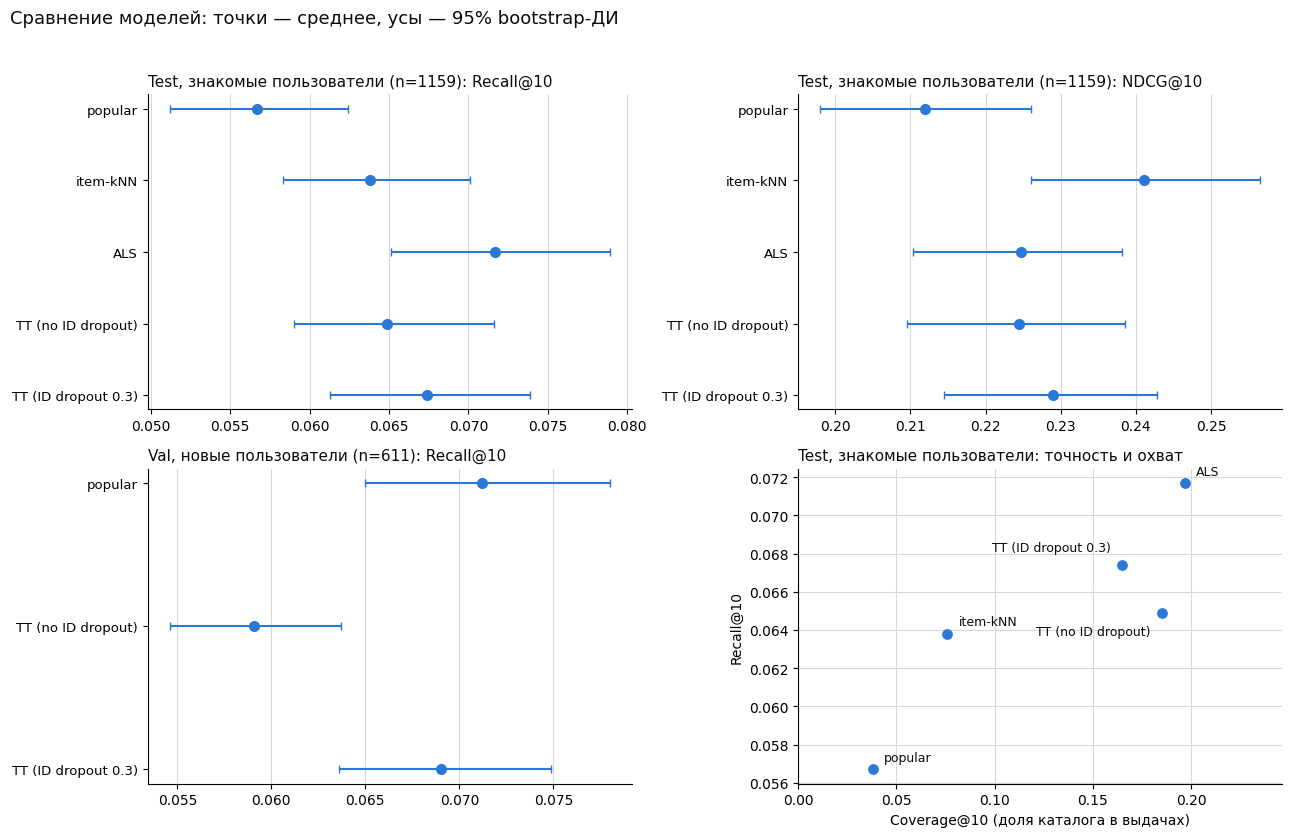

In [25]:
import os
import matplotlib.pyplot as plt

BLUE, INK, GRID = "#2a78d6", "#0b0b0b", "#d9d8d4"

def ci_bounds(s):
    lo, hi = s.strip("[]").split(", ")
    return float(lo), float(hi)

def style(ax, title):
    ax.set_title(title, fontsize=11, color=INK, loc="left")
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

def forest(ax, df, metric, title):
    df = df.iloc[::-1]                       # первая модель сверху
    val = df[metric].values
    lo, hi = (np.array(x) for x in zip(*df[f"{metric}_ci"].map(ci_bounds)))
    y = np.arange(len(df))
    ax.errorbar(val, y, xerr=[val - lo, hi - val], fmt="o", color=BLUE,
                ecolor=BLUE, elinewidth=1.5, capsize=3, markersize=7)
    ax.set_yticks(y); ax.set_yticklabels(df["model"], fontsize=9.5)
    style(ax, title)

warm_t = summary_test[summary_test.segment == "warm"]
cold_v = summary_val[summary_val.segment == "cold"]
n_w, n_c = int(warm_t.users.iloc[0]), int(cold_v.users.iloc[0])

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), facecolor="white")
forest(axes[0, 0], warm_t, "recall", f"Test, знакомые пользователи (n={n_w}): Recall@10")
forest(axes[0, 1], warm_t, "ndcg",   f"Test, знакомые пользователи (n={n_w}): NDCG@10")
forest(axes[1, 0], cold_v, "recall", f"Val, новые пользователи (n={n_c}): Recall@10")

ax = axes[1, 1]
ax.scatter(warm_t["coverage"], warm_t["recall"], color=BLUE, s=45, zorder=3)
offsets = {"popular": (8, 6), "item-kNN": (8, 6), "ALS": (8, 6),
           "TT (no ID dropout)": (-8, -16), "TT (ID dropout 0.3)": (-8, 10)}
for _, r in warm_t.iterrows():
    dx, dy = offsets.get(r["model"], (8, 6))
    ax.annotate(r["model"], (r["coverage"], r["recall"]), textcoords="offset points",
                xytext=(dx, dy), fontsize=9, color=INK, ha="left" if dx > 0 else "right")
ax.set_xlabel("Coverage@10 (доля каталога в выдачах)", fontsize=10)
ax.set_ylabel("Recall@10", fontsize=10)
ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.set_title("Test, знакомые пользователи: точность и охват", fontsize=11, color=INK, loc="left")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_xlim(0, warm_t["coverage"].max() * 1.25)

fig.suptitle("Сравнение моделей: точки — среднее, усы — 95% bootstrap-ДИ", fontsize=13, color=INK, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.96))
os.makedirs("assets", exist_ok=True)
fig.savefig("assets/results.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

---
## 8. Выводы, ограничения, дальнейшие шаги

### Что мы выяснили

1. **Популярное — сильный бейзлайн.** Метрики точности поощряют популярность по построению (чтобы оценить фильм, его надо сначала увидеть), поэтому ему трудно проиграть, особенно на новых пользователях.
2. **Персонализация даёт выигрыш на знакомых пользователях, но порядок моделей зависит от метрики.** Наибольший Recall@10 у ALS, наибольший NDCG@10 у item-kNN; ALS и kNN различимы по обеим метрикам, причём в разные стороны (на тесте). Возможное объяснение (гипотеза, не проверено): попадания kNN сконцентрированы в верхних позициях списка, а ALS чаще находит релевантные фильмы, но ставит их ниже.
3. **Двухбашенная модель не обошла ALS.** На этих данных и с этими признаками разница с ALS статистически не различима (при одном зерне обучения). Это нормальный результат: главное преимущество two-tower — работа с признаками и холодным стартом, а масштабируемость при retrieval здесь не проверяется.
4. **Смещение выборки реально.** Без logQ-коррекции модель теряет почти всю точность, и именно из-за неё без диагностики можно ошибочно принять высокий охват за разнообразие.
5. **ID dropout нужен, чтобы работать с новыми пользователями**, но популярное для них остаётся неотразимым соперником.
6. **Точность и разнообразие — это компромисс.** Одну модель нельзя выбрать по одной метрике: нужно смотреть на точность, охват и популярность рекомендованного вместе.

### Ограничения

* **Нет показов.** MovieLens — это оценки, а не реальные показы: мы не знаем, что пользователю показывали и не понравилось. «Нерелевантно» здесь означает «не оценил высоко», поэтому абсолютные метрики занижены, а оценка смещена в сторону популярного.
* **Возраст данных.** Данные 2000–2003 годов, в них один тип интерфейса и один тип пользователей.
* **Один запуск на модель.** ALS и двухбашенные модели обучались на одном зерне. Bootstrap покрывает шум от выбора пользователей, но не от случайности обучения. Для строгих выводов нужно несколько зёрен.
* **Двухбашенная модель не настраивалась.** Размер эмбеддинга, температура $\tau$, число эпох, архитектура башен и размер батча взяты «разумными по умолчанию».
* **Новые пользователи на тесте — всего 29.** Интервалы для этого среза очень широкие; выводы о нём опираются на val (n = 611).
* **Новые фильмы.** Примерно 1.0% фильмов в тесте не встречались в обучении, и модели не могут их рекомендовать. В нашей постановке они всегда считаются «промахами».
* **Однозначного «победителя» нет.** Выбор модели зависит от того, что важнее: Recall, качество порядка в начале списка, охват каталога или работа с новыми пользователями.

### Что можно добавить дальше

* Второй этап — **ранкер** (например, градиентный бустинг) поверх кандидатов, отобранных retrieval-моделью, и сравнение с одностадийными решениями.
* **Контентные признаки фильма** (название, текстовые эмбеддинги) для лечения холодного старта по фильмам.
* **Последовательные модели** (GRU4Rec, SASRec), которые используют порядок оценок пользователя, и история в user-башне.
* **ANN-индекс** (FAISS) для быстрого поиска ближайших векторов и сравнение точного и приближённого поиска.
* **Диверсификация** выдачи (например, MMR) и явная оптимизация компромисса точность/охват.
* **Несколько зёрен** и усреднение, настройка двухбашенной модели, калибровка вероятностей.

### Литература

1. Harper, F. M., Konstan, J. A. *The MovieLens Datasets: History and Context.* ACM TiiS, 2015.
2. Sarwar, B., Karypis, G., Konstan, J., Riedl, J. *Item-based collaborative filtering recommendation algorithms.* WWW, 2001.
3. Hu, Y., Koren, Y., Volinsky, C. *Collaborative Filtering for Implicit Feedback Datasets.* ICDM, 2008.
4. Koren, Y., Bell, R., Volinsky, C. *Matrix Factorization Techniques for Recommender Systems.* IEEE Computer, 2009.
5. Yi, X. et al. *Sampling-Bias-Corrected Neural Modeling for Large Corpus Item Recommendations.* RecSys, 2019.
6. Järvelin, K., Kekäläinen, J. *Cumulated Gain-Based Evaluation of IR Techniques.* ACM TOIS, 2002.
7. Cremonesi, P., Koren, Y., Turrin, R. *Performance of Recommender Algorithms on Top-N Recommendation Tasks.* RecSys, 2010.
8. Ferrari Dacrema, M., Cremonesi, P., Jannach, D. *Are We Really Making Much Progress? A Worrying Analysis of Recent Neural Recommendation Approaches.* RecSys, 2019.
9. Efron, B. *Bootstrap Methods: Another Look at the Jackknife.* The Annals of Statistics, 1979.